# Практична робота № 7
## Критичний аудит ML-рішення, створеного за допомогою ШІ або AutoML
**Ковальчук · ІПЗс-24-1 · варіант 5 · Бедратюк Л.П.**

Об'єкт аудиту — рішення ЛР № 6 (AutoML FLAML → `Pipeline(SimpleImputer → StandardScaler → LogisticRegression(C=0.1))`) у зафіксованій версії
коміту `81445e2`; `lab06/` не змінювався. Notebook лише читає артефакти `results/` і `figures/`, а ключові метрики перераховує наживо;
повний запуск — `python pr07_audit.py`. Код і текст підготовлено за допомогою Claude Code; рішення й межі допомоги — в `AI_USAGE.md`.
Позитивний клас y=1 — malignant (у `load_breast_cancer` malignant закодовано як 0, тому ціль аудиту — `1 − target`).

In [1]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.datasets import load_breast_cancer

ROOT = Path.cwd() if (Path.cwd() / "results").is_dir() else Path.cwd().parent
assert (ROOT / "results" / "verdict.json").is_file(), "run pr07_audit.py first"
sys.path.insert(0, str(ROOT))
import audit_core as A

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
R = ROOT / "results"
CFG = json.loads((ROOT / "configs" / "audit_config.json").read_text(encoding="utf-8"))
SUM = json.loads((R / "summary.json").read_text(encoding="utf-8"))
def table(name, **kw):
    return pd.read_csv(R / name, **kw)
def jload(name):
    return json.loads((R / name).read_text(encoding="utf-8"))
def picture(name):
    display(Image(filename=str(ROOT / "figures" / name)))
def say(text):
    display(Markdown(text))

## 1. Об'єкт аудиту, версія й комплектність

In [2]:
fro = table("frozen_object.csv")
say(f"Зафіксований коміт: `{CFG['object']['frozen_commit']}`. Файлів handoff: {len(fro)}; "
    f"байт-ідентичні: {SUM['frozen_info']['files_identical_bytes']}, відрізняються лише закінченнями рядків (autocrlf): "
    f"{SUM['frozen_info']['files_line_endings_only']}, змінені: {SUM['frozen_info']['files_different']}.")
display(fro[["file", "bytes", "worktree_vs_commit", "last_changed_in_commit", "sha256"]].assign(sha256=lambda d: d.sha256.str[:16] + "…"))
inv = table("inventory.csv")
say(f"Інвентаризація: присутні {int(inv.present.sum())} із {len(inv)} елементів.")
display(inv)

Зафіксований коміт: `81445e2e18764af176e48fba231ca857c412f486`. Файлів handoff: 14; байт-ідентичні: 4, відрізняються лише закінченнями рядків (autocrlf): 10, змінені: 0.

,file,bytes,worktree_vs_commit,last_changed_in_commit,sha256
0,MODEL_CARD.md,3911,line_endings_only,35ada0b,54a446f0a9f99f0c…
1,config.json,799,identical,35ada0b,1887300778b787a9…
2,cv_metrics.csv,2056,line_endings_only,35ada0b,752226a209c1abc8…
3,data_provenance.json,1257,line_endings_only,35ada0b,2d25a106e09b973f…
4,data_schema.json,4574,line_endings_only,35ada0b,801b5b5a3eeb79a5…
5,decision.sha256,66,line_endings_only,35ada0b,c485201ef60dd7f8…
6,decision_record.json,2414,identical,35ada0b,62caba19558d196b…
7,environment.json,278,line_endings_only,e1ccfc4,aeaa46ad350fc2b0…
8,inference.py,821,line_endings_only,35ada0b,cc685f74fbe8b035…
9,inference_example.json,1553,line_endings_only,35ada0b,af7609db065f33cd…


Інвентаризація: присутні 16 із 16 елементів.

,item,path,present,note
0,дані: snapshot,lab06/data/README.md,True,дані не копіюються; sklearn.load_breast_cancer + SHA-256 у data_provenance.json
1,split ids,lab06/handoff/split_ids.csv,True,NaN
2,код навчання,lab06/experiment.py,True,NaN
3,код запуску,lab06/run_experiment.py,True,NaN
4,конфігурація,lab06/handoff/config.json,True,NaN
5,залежності,lab06/handoff/requirements.txt,True,NaN
6,модель,lab06/handoff/pipeline.joblib,True,NaN
7,схема входу,lab06/handoff/data_schema.json,True,NaN
8,контрольний приклад,lab06/handoff/inference_example.json,True,NaN
9,inference,lab06/handoff/inference.py,True,NaN


## 2. Реєстр тверджень

,id,claim,evidence_level,criteria_passed,verdict
0,C-01,"На закритому test (114 записів) модель має AP=0.9966, ROC-AUC=0.9977, CM=[[72,0],[2,40...",3,3/3,підтверджено
1,C-02,Test не використовувався для пошуку чи вибору; рішення заморожене (хеш) до відкриття t...,3,5/6,підтверджено частково
2,C-03,"Модель узагальнює на нові дані: CV AP 0.9942 ± 0.0058, test AP 0.9966, значно вище bas...",3,4/5,підтверджено частково
3,C-04,AutoML-кандидат (C=0.1) і Manual (C=1.0) практично еквівалентні: |ΔAP| < ε=0.01.,4,2/2,підтверджено
4,C-05,Пакет передачі повний і його цілісність забезпечена SHA-256 рішення.,2,2/3,підтверджено частково
5,C-06,"inference.py перевіряє контракт входу: 30 ознак у порядку схеми, скінченні, невід'ємні.",4,1/4,підтверджено частково
6,C-07,Inference потребує лише sklearn/numpy/joblib; flaml/xgboost/lightgbm потрібні тільки д...,3,2/3,підтверджено частково
7,C-08,"Дані: 569 записів, 212 malignant, split 455/114 stratified, без дублікатів/пропусків; ...",3,5/5,підтверджено
8,C-09,Єдина узгоджена вершина важливості ознак — texture_worst (permutation importance).,4,1/2,підтверджено частково
9,C-10,Test використано один раз.,2,1/2,підтверджено частково


Деталі (джерело, незалежна перевірка, критерії прийняття, доказ) — у `results/claims.csv`.

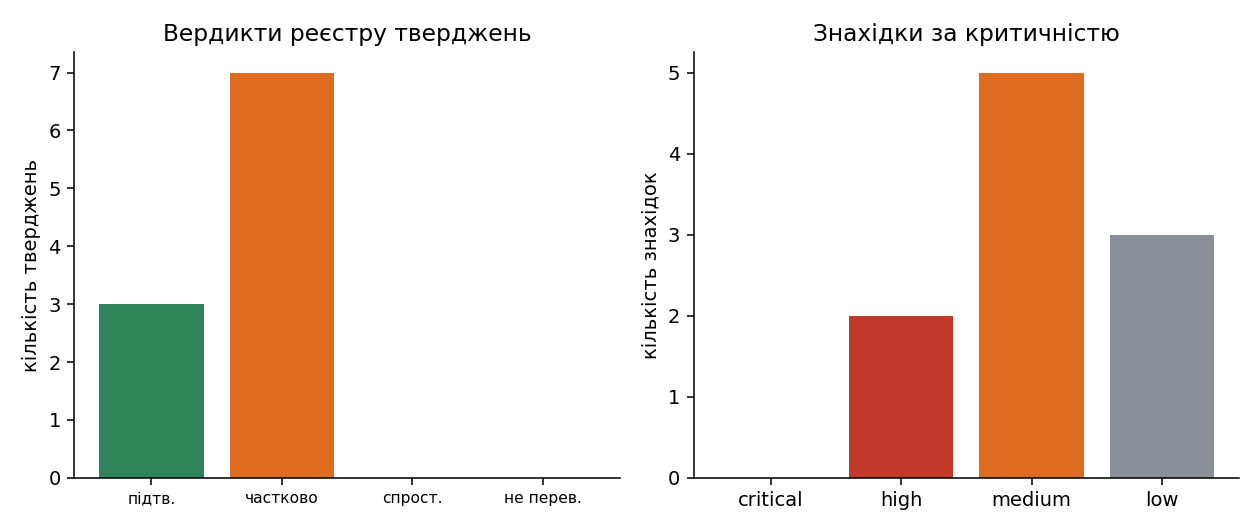

In [3]:
claims = table("claims.csv")
display(claims[["id", "claim", "evidence_level", "criteria_passed", "verdict"]])
say("Деталі (джерело, незалежна перевірка, критерії прийняття, доказ) — у `results/claims.csv`.")
picture("09_claims_findings.png")

**Рисунок 9.** Ліворуч — розподіл вердиктів тверджень, праворуч — знахідок за критичністю. Жодне твердження не спростовано повністю,
але більшість підтверджена лише частково: числа відтворюються, а умови їх застосування (контракт входу, незалежність test, цілісність пакета) мають прогалини.

## 3. Чистий запуск

In [4]:
cr = jload("clean_run.json")
rows = [{"спроба": a["name"], "довжина шляху venv": a["venv_path_length"], "pip exit": a["pip_exit"], "pip, с": a["pip_s"],
         "пакетів": a["n_installed"], "запуск exit": a["run_exit"], "успіх": a["success"]} for a in cr["attempts"]]
display(pd.DataFrame(rows))
say(f"Python: {cr['attempts'][0]['python']}. У спробі A pip завершився помилкою довгого шляху (Windows), проте `inference.py` у частково встановленому "
    "venv дав коректний результат — тому успіх фіксується лише за трьома ознаками разом (venv, pip, запуск).")

,спроба,довжина шляху venv,pip exit,"pip, с",пакетів,запуск exit,успіх
0,A_full_requirements_long_path,122,1,234.2,112,0,False
1,B_full_requirements_short_path,41,0,204.7,115,0,True
2,C_fixed_minimal_requirements,44,0,60.4,8,0,True


Python: Python 3.12.0. У спробі A pip завершився помилкою довгого шляху (Windows), проте `inference.py` у частково встановленому venv дав коректний результат — тому успіх фіксується лише за трьома ознаками разом (venv, pip, запуск).

## 4. Дані, leakage, протокол

,value
n,569
n_features,30
positives,212
negatives,357
sklearn_target_malignant_code,0
train_n,455
test_n,114
train_pos,170
test_pos,42
train_pos_rate,0.373626


,check,result,expected,ok
0,id overlap train/test,0,0,True
1,exact duplicate rows (all data),0,0,True
2,identical train/test feature rows,0,0,True
3,max |r| with target (signal only),0.7863,< 0.9,True
4,test rows closer than near-duplicate distance to a train row,0,0,True
5,preprocessing is inside the Pipeline object,SimpleImputer->StandardScaler->LogisticRegression,"imputer, scaler before model",True
6,scaler mean = train mean (max |delta|),0.00e+00,<= 1e-9,True
7,scaler mean differs from full-data mean (max |delta|),9.986e+00,> 1e-6,True
8,scaler n_samples_seen_ equals train size,455,455,True
9,config flags test_used_for_search/selection are false,False/False,False/False,True


,stage,data,used_for_decision,evidence
0,"fit (imputer, scaler, LR)","train, 455 записів",так,scaler.mean_ == середнє train (Δ=0.0e+00)
1,"selection (family, C)",вкладена CV на train: 5 outer × 3 inner,так,decision_record.json; правило відтворено з fold_metrics.csv
2,threshold tuning,не виконувалось; фіксований 0.5,ні,config.json: threshold=0.5
3,interpretation (permutation importance),outer-validation частини train,так,lab06 README §8; test не використано
4,freeze рішення,decision_record.json + decision.sha256,—,"хеш лише рішення, не моделі"
5,test (вибрана модель),"114 записів, один раз для вибраної моделі",оцінка,test_metrics.json
6,test (другий фіналіст),"114 записів після freeze, AUDIT_ONLY",оцінка,test_audit_other_finalist.json
7,"аудит ПР7: відтворення, stability, помилки",test + train (лише читання/оцінка),оцінка,жодне рішення про модель не змінюється


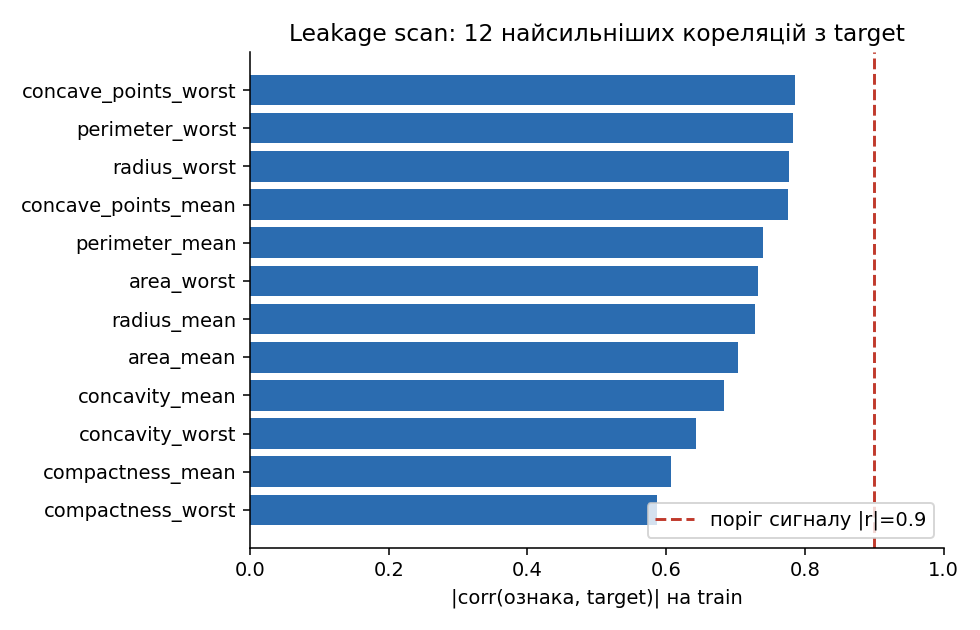

In [5]:
da = jload("data_audit.json")
display(pd.Series({k: v for k, v in da.items() if k != "raw_sha256"}).to_frame("value"))
display(table("leakage_checks.csv"))
display(table("dataflow.csv"))
picture("01_leakage_correlations.png")

**Рисунок 1.** Найбільша |r| з target на train — менша за поріг сигналу 0.9, тож проксі-ознак немає; кореляція лишається лише сигналом,
а висновок спирається на походження ознак і структуру протоколу (scaler навчено на train, preprocessing усередині Pipeline).
Негативні рядки таблиці — відсутність SHA-256 моделі та відсутність групових/часових ідентифікаторів.

## 5. Незалежні метрики, baseline, відтворення

,model,split,n,positive_n,ap,roc_auc,f1,precision,recall,balanced_accuracy,brier,log_loss,tn,fp,fn,tp
0,dummy_prior,test,114,42,0.3684,0.5000,0.0000,0.0000,0.0000,0.5000,0.2327,0.6582,72,0,42,0
1,frozen_joblib,test,114,42,0.9966,0.9977,0.9756,1.0000,0.9524,0.9762,0.0234,0.0948,72,0,2,40
2,refit_on_train,test,114,42,0.9966,0.9977,0.9756,1.0000,0.9524,0.9762,0.0234,0.0948,72,0,2,40
3,dummy_prior,train_resubstitution,455,170,0.3736,0.5000,0.0000,0.0000,0.0000,0.5000,0.2340,0.6609,285,0,170,0
4,frozen_joblib,train_resubstitution,455,170,0.9952,0.9960,0.9731,0.9879,0.9588,0.9759,0.0209,0.0886,283,2,7,163


,metric,reported,reproduced,abs_delta,within_tol
0,ap,0.9965986394557824,0.9965986394557824,0.0,True
1,roc_auc,0.9976851851851852,0.9976851851851852,0.0,True
2,f1,0.975609756097561,0.975609756097561,0.0,True
3,precision,1.0,1.0,0.0,True
4,recall,0.9523809523809523,0.9523809523809523,0.0,True
5,balanced_accuracy,0.9761904761904762,0.9761904761904762,0.0,True
6,brier,0.023365471064195696,0.023365471064195696,0.0,True
7,log_loss,0.09478851049675145,0.09478851049675145,0.0,True
8,confusion_matrix,"[[72, 0], [2, 40]]","[[72, 0], [2, 40]]",0.0,True


Наживо: AP=0.9966, ROC-AUC=0.9977, CM=[[72, 0], [2, 40]]; max |Δ| проти test_metrics.json = 0.0e+00 (допуск 1e-09).

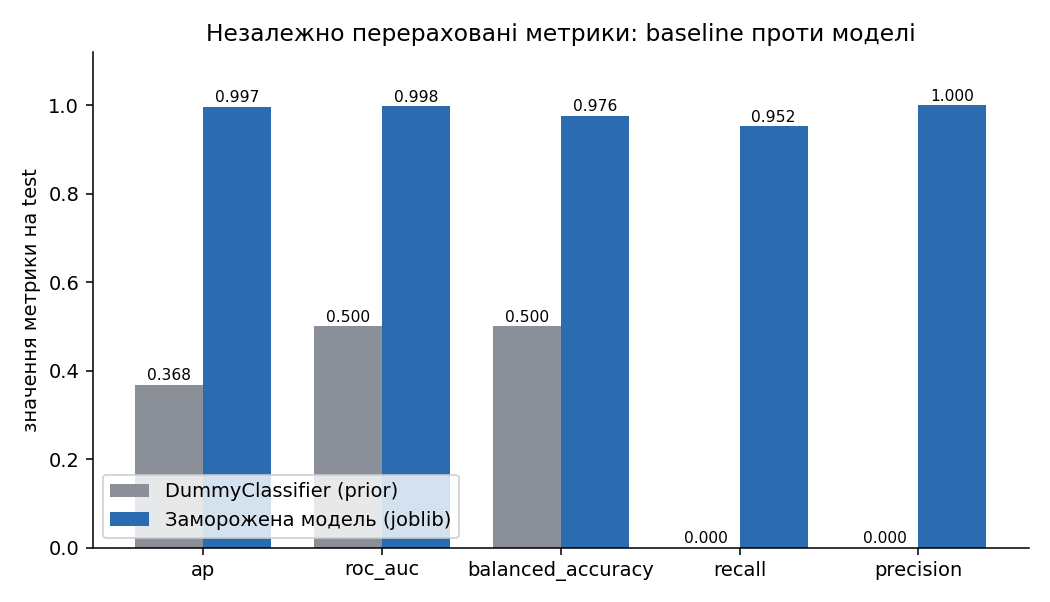

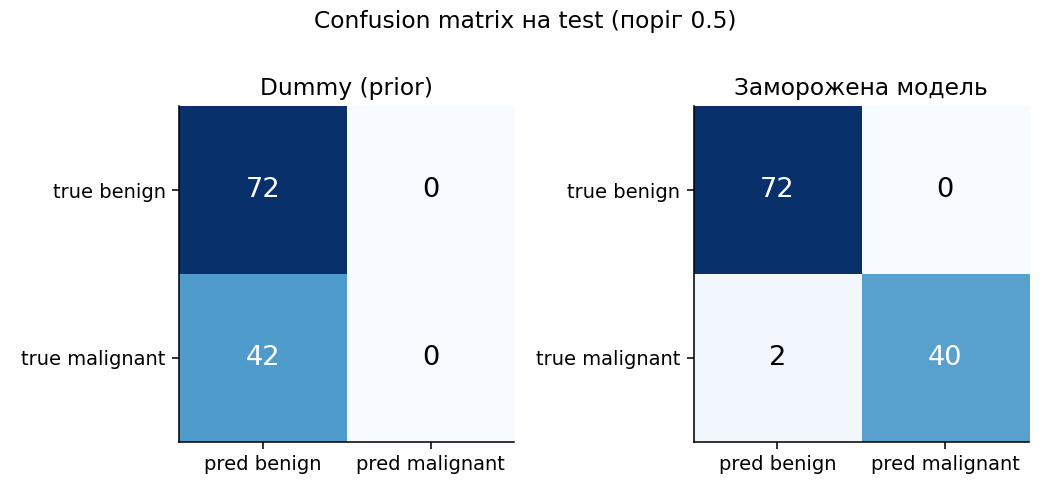

In [6]:
ind = table("independent_metrics.csv")
display(ind.round(4))
rep = table("reproduction_delta.csv")
display(rep)
# live recomputation, independent of the stored tables
d = load_breast_cancer()
y = A.audit_target(d.target)
split = pd.read_csv(ROOT.parent / "lab06" / "handoff" / "split_ids.csv")
te = split[split.part == "test"].id.to_numpy()
model = joblib.load(ROOT.parent / "lab06" / "handoff" / "pipeline.joblib")
live = A.evaluate_model(model, d.data[te], y[te], 0.5)
say(f"Наживо: AP={live['ap']:.4f}, ROC-AUC={live['roc_auc']:.4f}, CM={live['confusion_matrix']}; "
    f"max |Δ| проти test_metrics.json = {rep[rep.metric != 'confusion_matrix'].abs_delta.max():.1e} (допуск {CFG['tolerances']['metric']:.0e}).")
picture("02_metrics_vs_baseline.png")
picture("04_confusion_matrices.png")

**Рисунки 2 і 4.** Dummy-baseline дає AP, що дорівнює частці malignant у test, ROC-AUC 0.5 і жодного знайденого malignant (42 FN). Модель на test
пропускає 2 malignant і не має хибнопозитивних. Метрики відтворено до машинної точності; це доводить відтворюваність заявлених чисел, але не узагальнення.

## 6. Невизначеність: repeated CV і bootstrap на test

,model,metric,n,mean,std,min,max,ci_low,ci_high
0,frozen_config,ap,15,0.9937,0.0058,0.9827,1.0000,0.9908,0.9964
1,frozen_config,roc_auc,15,0.9949,0.0055,0.9840,1.0000,0.9921,0.9973
2,frozen_config,balanced_accuracy,15,0.9622,0.0216,0.9265,1.0000,0.9516,0.9729
4,frozen_config,recall,15,0.9314,0.0426,0.8529,1.0000,0.9098,0.9529
7,dummy_prior,ap,15,0.3736,0.0000,0.3736,0.3736,0.3736,0.3736
8,dummy_prior,roc_auc,15,0.5000,0.0000,0.5000,0.5000,0.5000,0.5000
9,dummy_prior,balanced_accuracy,15,0.5000,0.0000,0.5000,0.5000,0.5000,0.5000
11,dummy_prior,recall,15,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
14,control_C1.0,ap,15,0.9951,0.0048,0.9847,1.0000,0.9927,0.9973
15,control_C1.0,roc_auc,15,0.9960,0.0047,0.9861,1.0000,0.9936,0.9981


,95% bootstrap CI на test
recall,"[0.8749335106382978, 1.0]"
ap,"[0.9864494705993572, 1.0]"
roc_auc,"[0.9911738445378152, 1.0]"
n_boot,2000


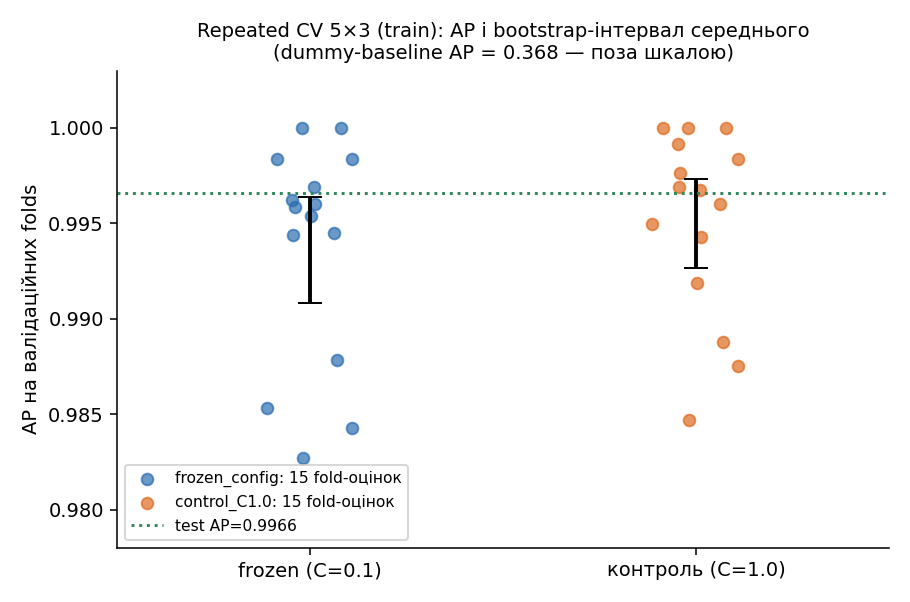

In [7]:
s = table("repeated_cv_summary.csv")
display(s[s.metric.isin(["ap", "roc_auc", "balanced_accuracy", "recall"])].round(4))
display(pd.Series(jload("test_bootstrap_ci.json")).to_frame("95% bootstrap CI на test"))
picture("03_repeated_cv.png")

**Рисунок 3.** П'ятнадцять fold-оцінок AP фіксованої конфігурації лежать вузько біля 0.994, а інтервал середнього не містить baseline; test AP потрапляє
в діапазон CV. Інтервал описує мінливість folds (вони залежні) і не усуває систематичних обмежень протоколу. На test (42 malignant) інтервал recall значно ширший.

## 7. Перевірка рекомендацій ШІ / AutoML

,id,recommendation,risk,control_test,actual_result,decision
0,R-1,Tie-break за розміром серіалізованого pipeline вибирає AutoML (lab06 AI_USAGE §4),Вибір за 3 байти може приховати реальну різницю якості,Парна різниця AP C=0.1 і C=1.0 на repeated CV 5×3 (train),"розміри 2171 vs 2174 байт; ΔAP=-0.0014, інтервал [-0.0029, -0.0001]","прийнято: різниця в межах ε, але вибір довільний"
1,R-2,Стабільність пошуку: три seeds дають те саме сімейство lrl2 (AI_USAGE §3),Стабільне сімейство не означає стабільного C,20 seeds внутрішньої 3-fold CV на train за сіткою C,"частоти найкращого C: {'1.0': 0.55, '0.1': 0.45}; різних значень: 2","змінено: сімейство стабільне, але C — ні (знахідка про довільність вибору C)"
2,R-3,"Хеш рішення + одноразовий запуск гарантують, що test не впливав на вибір (AI_USAGE §2)","Хеш доводить байти, не час і не зв'язок із моделлю",scaler.mean_ vs середнє train/усіх даних; refit на train → коефіцієнти; відтворення пр...,"Δscaler(train)=0.0e+00, Δscaler(all)=1.0e+01; Δcoef=0.0e+00; правило відтворено=True; ...",прийнято частково: модель відповідає train-only протоколу; час не доведено
3,R-4,"Закріпити у requirements flaml/xgboost/lightgbm, бо FLAML їх імпортує; inference потре...",Надлишкові залежності ламають чисте встановлення,Чисті venv: повний і мінімальний requirements; скан об'єкта моделі,"об'єкт моделі: ['numpy', 'sklearn']; A pip exit=1, B pip exit=0, мінімальний набір suc...",змінено: для inference достатньо мінімального набору


,seed,best_C,ap_C0.01,ap_C0.1,ap_C1.0,ap_C10.0
0,1000,1.0,0.9890,0.9938,0.9948,0.9887
1,1001,0.1,0.9899,0.9926,0.9919,0.9891
2,1002,1.0,0.9896,0.9926,0.9936,0.9916
3,1003,1.0,0.9893,0.9942,0.9956,0.9944
4,1004,0.1,0.9883,0.9925,0.9913,0.9884
5,1005,1.0,0.9898,0.9923,0.9944,0.9929
6,1006,0.1,0.9895,0.9932,0.9920,0.9912
7,1007,1.0,0.9899,0.9932,0.9944,0.9925


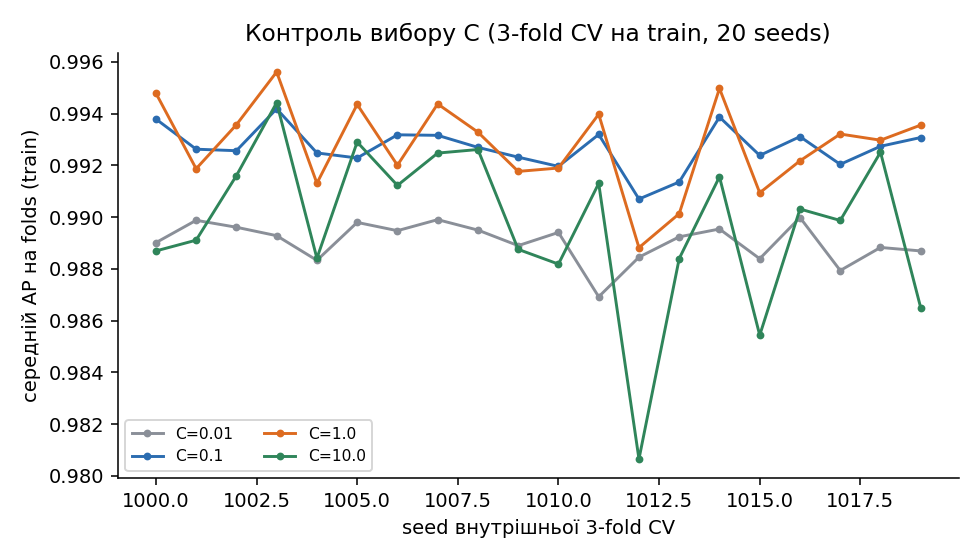

In [8]:
display(table("ai_recommendation_checks.csv"))
display(table("selection_control.csv").round(4).head(8))
picture("10_selection_control.png")

**Рисунок 10.** Лінії C=0.1 і C=1.0 майже збігаються, а найкраще C змінюється між seeds, тому вибір C=0.1 практично довільний (і так сформульовано в lab06).

## 8. Стійкість

,ap,roc_auc,recall,precision,disagreement_D,mean_abs_dp,max_abs_dp
mean,0.9967,0.9978,0.9452,0.9976,0.0088,0.0135,0.1322
std,0.0011,0.0008,0.0269,0.0075,0.0080,0.0042,0.0504
min,0.9940,0.9957,0.8810,0.9756,0.0000,0.0079,0.0781
max,0.9979,0.9987,0.9762,1.0000,0.0263,0.0258,0.2558


,feature,mean_drop_ap,std,mean_rank,freq_top1,freq_topk
0,texture_worst,0.0055,0.0018,1.50,0.75,1.00
1,radius_se,0.0032,0.0018,4.55,0.05,0.75
2,area_se,0.0031,0.0028,8.30,0.15,0.50
3,texture_mean,0.0026,0.0013,5.95,0.00,0.55
4,radius_worst,0.0021,0.0010,6.70,0.00,0.35
5,symmetry_worst,0.0020,0.0022,11.60,0.05,0.40
6,area_worst,0.0017,0.0009,8.60,0.00,0.25
7,perimeter_worst,0.0016,0.0009,9.75,0.00,0.10


Ранжування важливості між перенавчаннями: Spearman 0.601, top-5 Jaccard 0.353.

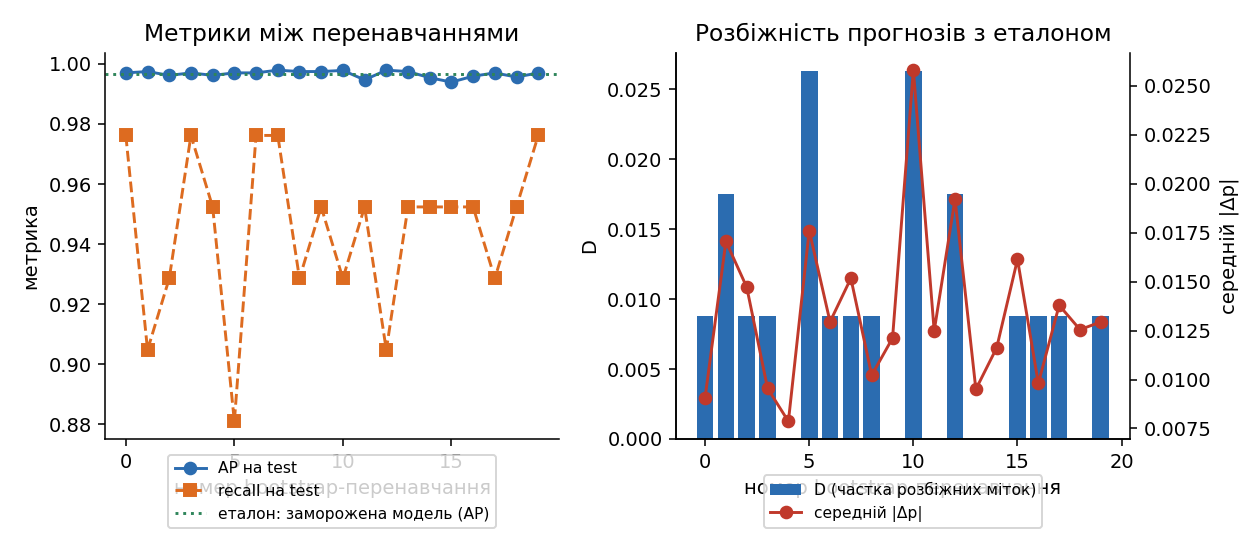

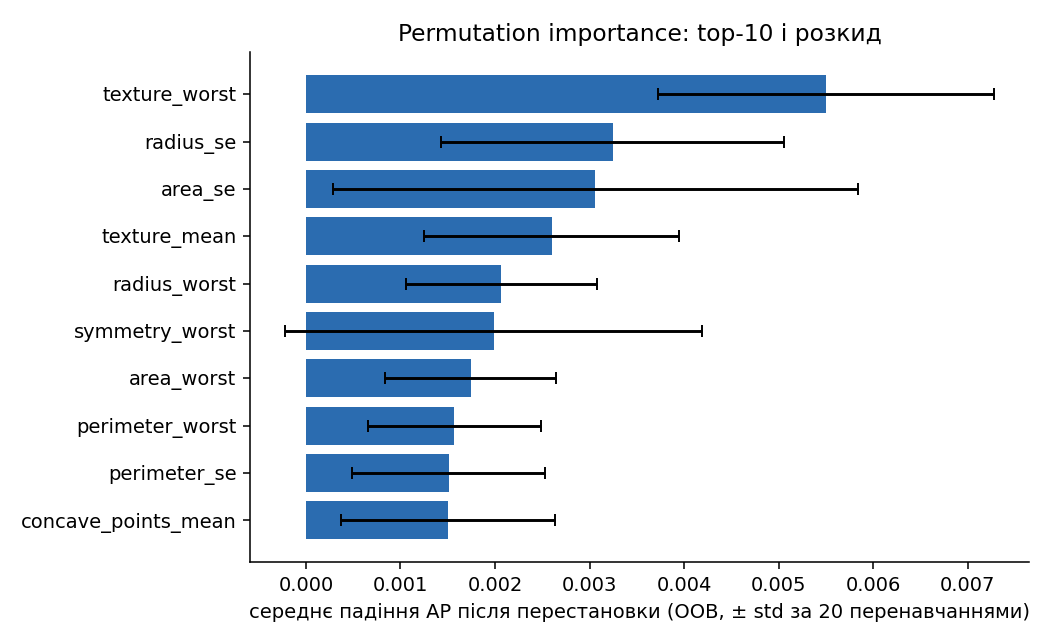

In [9]:
runs = table("stability_runs.csv")
display(runs[["ap", "roc_auc", "recall", "precision", "disagreement_D", "mean_abs_dp", "max_abs_dp"]].describe().loc[["mean", "std", "min", "max"]].round(4))
imp = table("importance_summary.csv")
display(imp.head(8).round(4))
say(f"Ранжування важливості між перенавчаннями: Spearman {SUM['rank_stability']['rank_mean_spearman']:.3f}, top-5 Jaccard {SUM['rank_stability']['rank_mean_topk_jaccard']:.3f}.")
picture("05_stability.png")
picture("06_permutation_importance.png")

**Рисунки 5 і 6.** AP майже не змінюється між перенавчаннями, а recall і конкретні мітки — змінюються (D до кількох відсотків, найбільший |Δp| на окремому об'єкті — десятки відсотків).
Важливість `texture_worst` найчастіше перша, але решта рангів нестійка (низький Jaccard), тож це чутливість моделі до перестановки, а не причина.

## 9. Аналіз помилок

,set,id,y,p,pred,is_error,margin,category,n_features_outside_train_range,max_abs_z,area_radius_ratio,baseline_wrong,control_C1_wrong,type,retrain_p_std,retrain_flip_rate
0,test,73,1,0.164,0,True,0.336,error,0,1.083,0.976,True,True,FN,0.041,0.00
1,test,86,1,0.613,1,False,0.113,near_threshold,0,1.816,0.984,True,False,correct,0.069,0.15
2,test,99,1,0.548,1,False,0.048,near_threshold+unstable_under_retrain,0,1.148,0.984,True,False,correct,0.050,0.20
3,test,205,1,0.425,0,True,0.075,error+near_threshold+unstable_under_retrain,0,1.551,0.998,True,True,FN,0.066,0.30
4,test,385,1,0.573,1,False,0.073,near_threshold+unstable_under_retrain,0,1.229,0.993,True,False,correct,0.078,0.25
5,test,455,0,0.365,0,False,0.135,near_threshold,0,2.637,0.991,False,True,correct,0.105,0.10
6,train_oof,38,1,0.280,0,True,0.220,confident_error_cv_oof,0,2.770,0.990,True,False,FN,NaN,NaN
7,train_oof,40,1,0.167,0,True,0.333,confident_error_cv_oof,0,1.268,0.992,True,True,FN,NaN,NaN
8,train_oof,135,1,0.153,0,True,0.347,confident_error_cv_oof,0,1.229,0.988,True,True,FN,NaN,NaN
9,train_oof,263,1,0.257,0,True,0.243,confident_error_cv_oof,0,1.427,0.991,True,True,FN,NaN,NaN


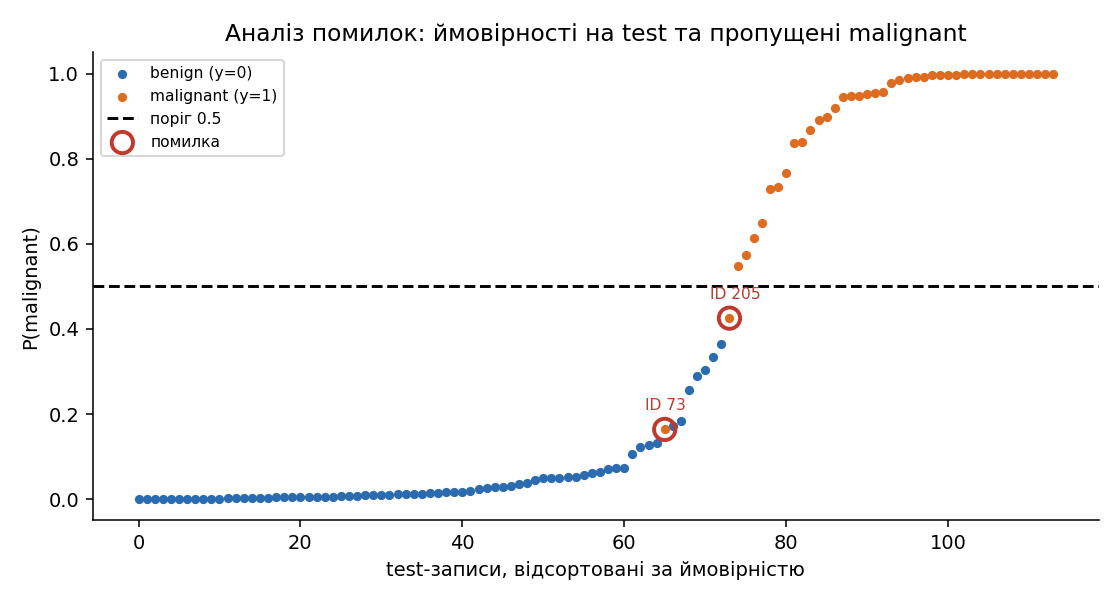

In [10]:
err = table("error_objects.csv")
display(err.round(3))
picture("07_error_analysis.png")

**Рисунок 7.** Обидва пропущені malignant (ID 73 і 205) лежать у зоні нижче порога; ID 205 ще й нестабільний між перенавчаннями. У CV на train найупевненіші помилки — теж FN.
Baseline цих помилок не виправляє: він пропускає всі malignant.

## 10. Негативні сценарії й виправлена версія

,scenario,expected,legacy_status,legacy_ok,hardened_status,hardened_ok
0,baseline_valid_record,accepted,accepted,True,accepted,True
1,missing_feature,rejected,rejected,True,rejected,True
2,extra_feature,rejected,rejected,True,rejected,True
3,wrong_type_text,rejected,rejected,True,rejected,True
4,numeric_string,rejected,accepted,False,rejected,True
5,none_value,rejected,rejected,True,rejected,True
6,nan_value,rejected,rejected,True,rejected,True
7,inf_value,rejected,rejected,True,rejected,True
8,reordered_fields,accepted,accepted,False,accepted,True
9,out_of_range_x10_radius,accepted_with_warning,accepted,False,accepted_with_warning,True


,fixed
model_sha256,b63381332edb446557779d0d3042cd4e3be973cbc9fd70a1682513fe9abc315b
identical_to_handoff,True
n_records,114
statuses,"{'accepted': 111, 'accepted_with_warning': 3}"
max_abs_dp_hardened_vs_original,0.0
labels_identical,True
metrics_identical,True
hardened_ap,0.996599
hardened_roc_auc,0.997685
hardened_cm,"[[72, 0], [2, 40]]"


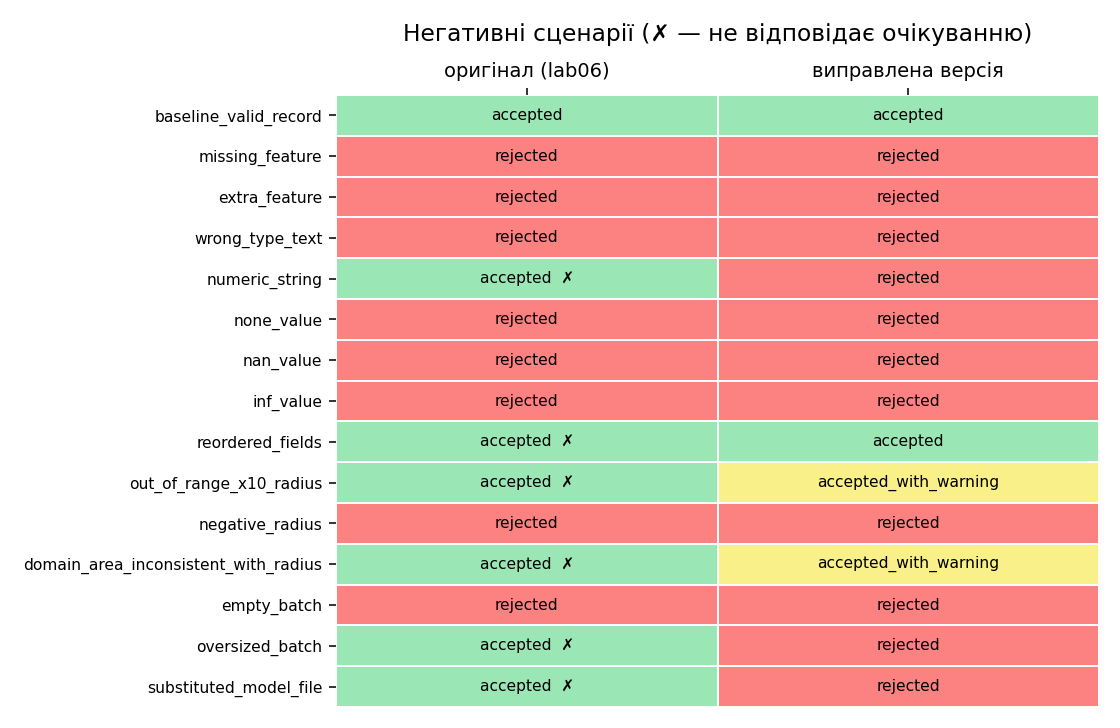

In [11]:
neg = table("negative_tests.csv")
display(neg[["scenario", "expected", "legacy_status", "legacy_ok", "hardened_status", "hardened_ok"]])
fe = jload("fixed_evaluation.json")
display(pd.Series({k: v for k, v in fe.items() if k not in ("sha256_file",)}).to_frame("fixed"))
picture("08_negative_tests.png")

**Рисунок 8.** Оригінальний `inference.py` відхиляє нечислові, NaN/inf, від'ємні й неповні входи, але мовчки приймає переставлені колонки, числові рядки, значення поза діапазоном,
геометрично неузгоджені записи, надмірний batch і підмінену модель. Виправлена версія відповідає очікуванням у всіх сценаріях, а її прогнози на test ідентичні.

## 11. Знахідки та вердикт

In [12]:
display(table("findings.csv")[["id", "severity", "status", "problem"]])
v = jload("verdict.json")
say(f"**Вердикт для початкового рішення: {v['verdict']}.** Після виправлень: {v['verdict_after_fixes']}. "
    f"Тверджень: {v['claims']}; знахідок: {v['findings_by_severity']}; блокуючі: {v['basis']['blocking_findings']}.")

,id,severity,status,problem
0,F-01,high,fixed,"Немає контрольної суми pipeline.joblib; decision.sha256 охоплює лише рішення, тому під..."
1,F-02,high,fixed,Inference приймає лише позиційний масив без імен ознак: переставлені колонки не виявля...
2,F-03,medium,fixed,Немає попередження про значення поза train-діапазоном і предметну неузгодженість (площ...
3,F-04,medium,fixed,"Повний requirements.txt із handoff не встановлюється чисто: він вимагає flaml, xgboost..."
4,F-05,medium,accepted_risk,Test ЛР6 не є «свіжим» щодо попередніх робіт курсу: більшість test-записів були у trai...
5,F-06,medium,accepted_risk,"Test малий (42 malignant): метрики за порогом 0.5 мають широкий інтервал, а 2 пропущен..."
6,F-07,medium,accepted_risk,Немає ідентифікатора пацієнта/групи та часу: залежність між записами одного пацієнта в...
7,F-08,low,documented,"Порядок «freeze → test» доведено лише побічно: рішення, модель і test-метрики потрапил..."
8,F-09,low,documented,Заява «test використано один раз» неточна: на test також оцінено другого фіналіста (AU...
9,F-10,low,documented,Вибір C=0.1 практично довільний: на 20 seeds внутрішньої 3-fold CV (train) C=0.1 обира...


**Вердикт для початкового рішення: потребує доопрацювання.** Після виправлень: прийнято з обмеженнями. Тверджень: {'підтверджено частково': 7, 'підтверджено': 3}; знахідок: {'medium': 5, 'low': 3, 'high': 2}; блокуючі: ['F-01', 'F-02'].